## Simulation SGS non-stationnaire avec clustering par Landuse

On peut parfois rencontrer un environnement où les statistiques spatiales ne sont pas uniformes sur l'ensemble d'une zone d'étude, c'est ce qu'on appelle la **non-stationnarité**. Par exemple, la teneur en plomb (Pb) peut présenter une variabilité spatiale plus marquée dans certaines zones et plus faible dans d'autres, selon le type d'occupation du sol.

Ce notebook met en œuvre une simulation SGS (Sequential Gaussian Simulation) avec **plusieurs variogrammes**, chacun assigné à une région différente. Les clusters utilisés ici sont directement définis par la variable catégorielle **Landuse**, déjà présente dans le jeu de données du Jura, ce qui permet d'associer un comportement spatial distinct à chaque type d'occupation du sol.

**Source** : Approche inspirée du tutoriel officiel GStatSim (non-stationary SGS, k-means clustering) — [gatorglaciology.github.io/gstatsimbook](https://gatorglaciology.github.io/gstatsimbook/7_non-stationary_SGS_example1.html)

In [16]:
"""
Bibliothèques nécessaires à la simulation géostatistique non-stationnaire.

numpy, pandas, matplotlib : manipulation de données et visualisation.
QuantileTransformer (sklearn) : anamorphose gaussienne (normal score).
skgstat : calcul et modélisation des variogrammes expérimentaux.
gstatsim : simulation géostatistique (cluster_sgs notamment).

""" 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import QuantileTransformer
import skgstat as skg
from skgstat import models
import gstatsim as gs

## 1. Rappel des données

La répartition spatiale de la teneur en Pb a déjà été présentée dans le notebook 01 (chargement et exploration). On rappelle ici uniquement les caractéristiques utiles à la suite de l'analyse : 259 points, sept métaux traces, et deux covariables catégorielles (Landuse, RockType).

In [17]:
"""
Chargement du jeu de données Jura, déjà exploré et nettoyé dans le
notebook 01. Aucune nouvelle visualisation n'est nécessaire ici.
"""

import sys
import os

sys.path.append(os.path.abspath(os.path.join("..", "..")))
import geostat_utils as gutils

data_jura = gutils.charger_donnees_jura()
print(f"Nombre de points : {len(data_jura)}")
print(f"Colonnes disponibles : {data_jura.columns.tolist()}")

Nombre de points : 259
Colonnes disponibles : ['X', 'Y', 'Landuse', 'RockType', 'Cd', 'Co', 'Cr', 'Cu', 'Ni', 'Pb', 'Zn']


## 2. Vérification des catégories de Landuse

Avant de calculer un variogramme distinct par catégorie de `Landuse`, il faut vérifier que chaque catégorie contient suffisamment de points. Un cluster avec trop peu de points (moins d'une dizaine) donnerait un variogramme statistiquement instable, voire impossible à ajuster.

In [18]:
# ---- Vérification du nombre de points par catégorie de Landuse ----
print(data_jura["Landuse"].value_counts().sort_index())

Landuse
1     33
2     56
3    165
4      5
Name: count, dtype: int64


## 3. Anamorphose gaussienne (transformation normal score)

La simulation géostatistique nécessite que la variable étudiée suive une distribution gaussienne. On applique donc une transformation normal score à la teneur en Pb, avant de calculer les variogrammes par cluster.

Contrairement aux notebooks 02 et 04 (où 9 valeurs aberrantes de Pb > 132 mg/kg avaient été filtrées), on conserve ici l'intégralité des 259 points : l'objectif de ce notebook est d'illustrer le clustering par Landuse.Le clustering lui-même (section 4) exclura séparément la catégorie Culture, trop peu représentée (5 points), ramenant le jeu à 254 points.

In [19]:
def preparer_donnees_pb(data):
    """
    Prépare les données de Pb pour la simulation non-stationnaire :
    extrait X, Y, Pb, Landuse, puis applique l'anamorphose gaussienne.

    Parameters
    ----------
    data : pandas.DataFrame
        Jeu de données Jura complet (data_jura).

    Returns
    -------
    df : pandas.DataFrame
        Sous-ensemble des données, avec la colonne NPb ajoutée
        (Pb transformé en distribution gaussienne).
    nst_trans : sklearn.preprocessing.QuantileTransformer
        Transformation ajustée, à conserver pour la back-transformation
        finale (retour à l'échelle réelle après simulation).
    """
    df = data[["X", "Y", "Pb", "Landuse"]].copy()

    data_pb = df["Pb"].values.reshape(-1, 1)
    nst_trans = QuantileTransformer(n_quantiles=len(df), output_distribution="normal").fit(data_pb)
    df["NPb"] = nst_trans.transform(data_pb)

    return df, nst_trans


df, nst_trans = preparer_donnees_pb(data_jura)
print(df[["Pb", "NPb"]].describe())

               Pb         NPb
count  259.000000  259.000000
mean    53.916602    0.000322
std     29.792158    1.081399
min     18.960000   -5.199338
25%     36.520000   -0.674490
50%     46.400000    0.000000
75%     60.400000    0.674502
max    229.560000    5.199338


## 4. Définition des clusters (catégories de Landuse)

Chaque cluster correspond ici à une catégorie de `Landuse`. Les catégories comptant moins de 10 points sont exclues, un nombre insuffisant pour ajuster un variogramme fiable. Les clusters retenus sont ensuite renumérotés de façon continue (0, 1, 2...), une contrainte technique de la fonction de simulation utilisée par la suite.

In [20]:
def definir_clusters_landuse(df, seuil_min=10):
    """
    Définit les clusters à partir de la variable Landuse, en excluant
    les catégories sous-représentées et en renumérotant les clusters
    retenus de façon continue (0, 1, 2...).

    Parameters
    ----------
    df : pandas.DataFrame
        Données contenant la colonne Landuse.
    seuil_min : int, optional
        Nombre minimal de points requis pour retenir une catégorie.
        Par défaut 10.

    Returns
    -------
    df : pandas.DataFrame
        Données filtrées (catégories exclues retirées), avec une
        nouvelle colonne K contenant le numéro de cluster renuméroté.
    clusters_valides : list
        Liste des catégories de Landuse retenues, dans l'ordre
        correspondant à la numérotation de K.
    """
    comptage = df["Landuse"].value_counts()
    clusters_valides = sorted([k for k in comptage.index if comptage[k] >= seuil_min])
    exclus = sorted(set(comptage.index) - set(clusters_valides))

    print(f"Clusters retenus (>= {seuil_min} points) : {clusters_valides}")
    print(f"Clusters exclus (< {seuil_min} points) : {exclus}")

    df = df[df["Landuse"].isin(clusters_valides)].copy()

    mapping_cluster = {landuse: i for i, landuse in enumerate(clusters_valides)}
    df["K"] = df["Landuse"].map(mapping_cluster).astype(int)

    print(f"Nombre de points conservés : {len(df)}")
    return df, clusters_valides


df, clusters_valides = definir_clusters_landuse(df)
clusters = sorted(df["K"].unique())
n_clusters = len(clusters)

Clusters retenus (>= 10 points) : [1, 2, 3]
Clusters exclus (< 10 points) : [4]
Nombre de points conservés : 254


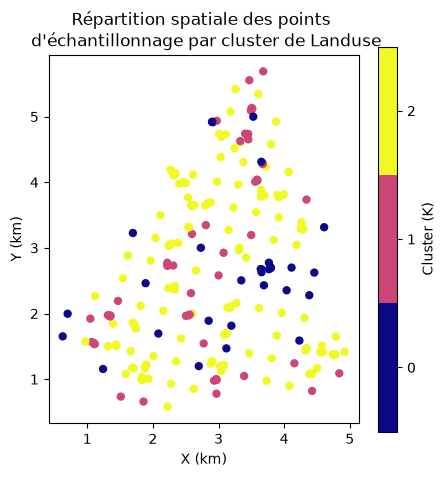

In [21]:
def afficher_clusters(df, n_clusters):
    """
    Affiche la répartition spatiale des points, colorés par cluster.
    """
    cmap = plt.get_cmap("plasma", n_clusters)
    plt.figure(figsize=(5, 5))
    im = plt.scatter(df["X"], df["Y"], c=df["K"], marker="o", s=25, cmap=cmap)
    im.set_clim(-0.5, n_clusters - 0.5)
    plt.title("Répartition spatiale des points \n d'échantillonnage par cluster de Landuse")
    plt.xlabel("X (km)")
    plt.ylabel("Y (km)")
    cbar = plt.colorbar(im, label="Cluster (K)")
    cbar.set_ticks(range(n_clusters))
    plt.axis("scaled")
    plt.show()

afficher_clusters(df, n_clusters)

## 5. Variogramme expérimental par cluster

Pour chaque cluster (catégorie de Landuse retenue), on calcule un variogramme expérimental distinct à partir des points qui lui
appartiennent, afin de capturer une structure de corrélation spatiale propre à chaque type d'occupation du sol.

In [22]:
def calculer_variogrammes_par_cluster(df, clusters, maxlag=3.0, n_lags=15):
    """
    Calcule un variogramme expérimental pour chaque cluster.

    Parameters
    ----------
    df : pandas.DataFrame
        Données contenant les colonnes X, Y, NPb et K (cluster).
    clusters : list of int
        Numéros de clusters à traiter (0, 1, 2...).
    maxlag : float, optional
        Distance maximale (km) prise en compte dans le variogramme.
        Par défaut 3.0.
    n_lags : int, optional
        Nombre de classes de distance. Par défaut 15.

    Returns
    -------
    variograms : dict
        Un objet skgstat.Variogram par cluster, indexé par son numéro.
    """
    variograms = {}
    for k in clusters:
        sous_df = df[df["K"] == k]
        coords = sous_df[["X", "Y"]].values
        valeurs = sous_df["NPb"].values
        V = skg.Variogram(coords, valeurs, bin_func="even", n_lags=n_lags,
                           maxlag=maxlag, normalize=False)
        variograms[k] = V
    return variograms


variograms = calculer_variogrammes_par_cluster(df, clusters)

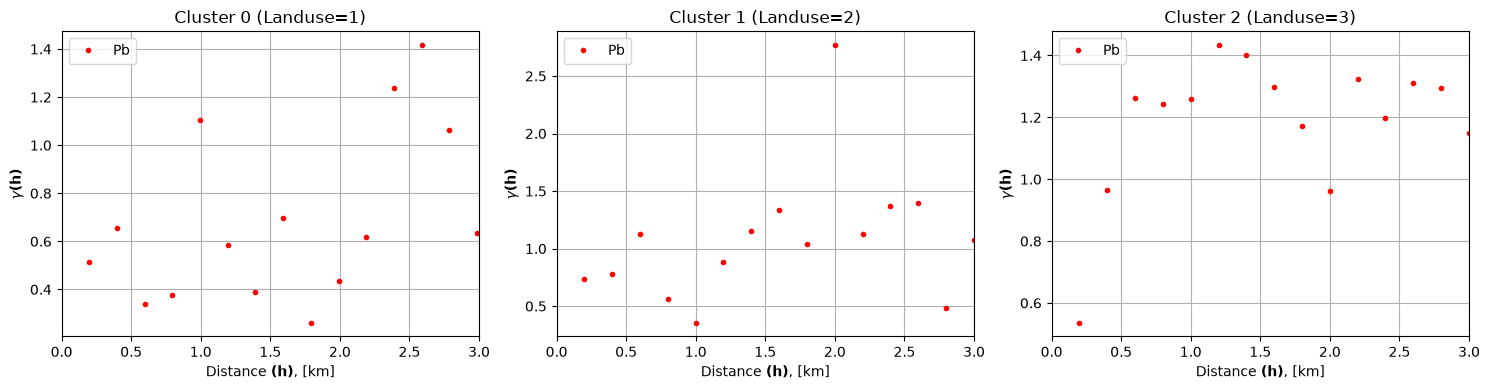

In [23]:
def afficher_variogrammes_experimentaux(variograms, clusters_valides, maxlag=3.0):
    """
    Affiche les variogrammes expérimentaux de chaque cluster, côte à côte.
    """
    fig, axs = plt.subplots(1, len(variograms), figsize=(5 * len(variograms), 4))
    if len(variograms) == 1:
        axs = [axs]

    for ax, (k, V) in zip(axs, variograms.items()):
        ax.plot(V.bins, V.experimental, ".", color="red", label="Pb")
        ax.set_xlabel(r"Distance $\bf(h)$, [km]")
        ax.set_ylabel(r"$\gamma \bf(h)$")
        ax.set_title(f"Cluster {k} (Landuse={clusters_valides[k]})")
        ax.legend(loc="upper left")
        ax.set_xlim([0, maxlag])
        ax.grid(True)

    plt.tight_layout()
    gutils.sauvegarder_figure("fig12_variogrammes_clusters.png") 
    plt.show()

afficher_variogrammes_experimentaux(variograms, clusters_valides)

## 6. Ajustement du modèle théorique de variogramme

Un modèle exponentiel est ajusté sur chaque variogramme expérimental, afin d'en extraire les paramètres (portée, palier) nécessaires à la simulation géostatistique.

Cluster 0 : portée=2.375 km, palier=0.863
Cluster 1 : portée=1.779 km, palier=1.273
Cluster 2 : portée=0.803 km, palier=1.267


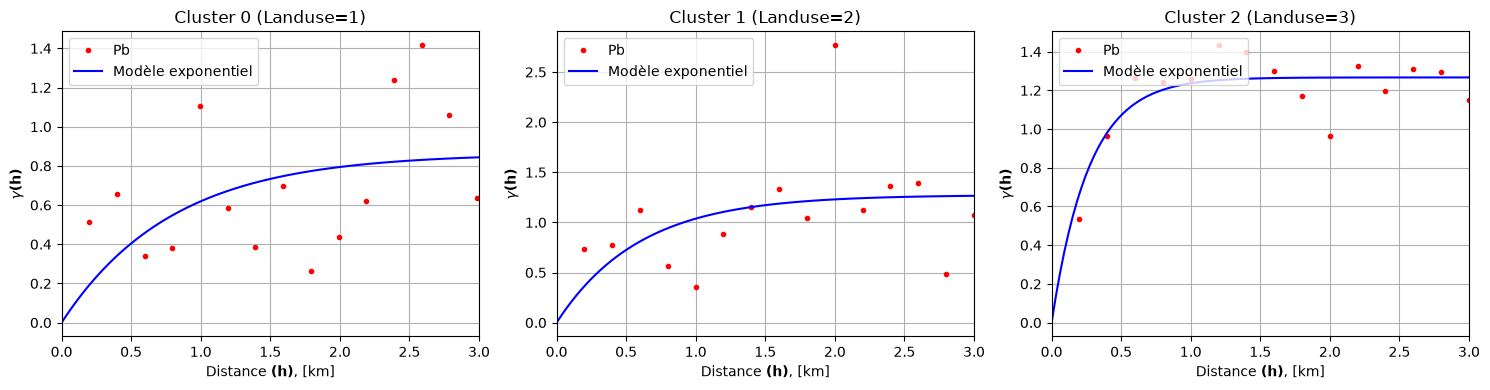

In [24]:
def ajuster_modeles_variogrammes(variograms):
    """
    Ajuste un modèle exponentiel sur chaque variogramme expérimental,
    et extrait ses paramètres.

    Parameters
    ----------
    variograms : dict
        Variogrammes expérimentaux calculés précédemment.

    Returns
    -------
    parametres : dict
        Pour chaque cluster, un dictionnaire {"range": ..., "sill": ...}.
    """
    parametres = {}
    for k, V in variograms.items():
        V.model = "exponential"
        parametres[k] = {"range": V.parameters[0], "sill": V.parameters[1]}
        print(f"Cluster {k} : portée={V.parameters[0]:.3f} km, palier={V.parameters[1]:.3f}")
    return parametres


def afficher_modeles_ajustes(variograms, parametres, clusters_valides, maxlag=3.0):
    """
    Affiche le variogramme expérimental et son modèle ajusté, par cluster.
    """
    fig, axs = plt.subplots(1, len(variograms), figsize=(5 * len(variograms), 4))
    if len(variograms) == 1:
        axs = [axs]

    lagh = np.linspace(0, maxlag, 100)
    for ax, (k, V) in zip(axs, variograms.items()):
        y = [models.exponential(h, parametres[k]["range"], parametres[k]["sill"], 0) for h in lagh]
        ax.plot(V.bins, V.experimental, ".", color="red", label="Pb")
        ax.plot(lagh, y, "-", color="blue", label="Modèle exponentiel")
        ax.set_xlabel(r"Distance $\bf(h)$, [km]")
        ax.set_ylabel(r"$\gamma \bf(h)$")
        ax.set_title(f"Cluster {k} (Landuse={clusters_valides[k]})")
        ax.legend(loc="upper left")
        ax.set_xlim([0, maxlag])
        ax.grid(True)

    plt.tight_layout()
    plt.show()


parametres = ajuster_modeles_variogrammes(variograms)
afficher_modeles_ajustes(variograms, parametres, clusters_valides)

## 7. Construction de la grille de prédiction

On construit une grille régulière couvrant le domaine d'étude (comme la grille 100×100 du notebook 04, mais ici la simulation sera assignée à un cluster différent selon la zone). La résolution est fixée à 0.05 km, un compromis raisonnable entre finesse de la carte et temps de calcul (~ 100×100 cellules).

In [25]:
# ---- Construction de la grille de prédiction ----
res = 0.05  # résolution de la grille
xmin, xmax = data_jura["X"].min(), data_jura["X"].max()
ymin, ymax = data_jura["Y"].min(), data_jura["Y"].max()

Pred_grid_xy = gs.Gridding.prediction_grid(xmin, xmax, ymin, ymax, res)

# Dimensions de la grille (déduites du nombre de valeurs uniques en X et en Y)
cols = len(np.unique(Pred_grid_xy[:, 0]))
rows = len(np.unique(Pred_grid_xy[:, 1]))

print(f"Grille de prédiction : {rows} x {cols} = {len(Pred_grid_xy)} points")

Grille de prédiction : 104 x 87 = 9048 points


## 8. Assemblage des paramètres de variogramme par cluster

`gstatsim` attend, pour chaque cluster, une liste `[azimuth, nugget, portée_majeure, portée_mineure, palier, type_modele]`. Comme les variogrammes ont été calculés de façon omnidirectionnelle (pas de direction préférentielle étudiée ici), la portée majeure et la portée mineure sont identiques (pas d'anisotropie modélisée).

In [26]:
# ---- Assemblage des paramètres de variogramme par cluster ----
azimuth = 0
nug = 0
vtype = "Exponential"

gammas = []
for k in clusters:
    portee = parametres[k]["range"]
    palier = parametres[k]["sill"]
    gammas.append([azimuth, nug, portee, portee, palier, vtype])

df_gamma = pd.DataFrame({"Variogram": gammas})
df_gamma

,Variogram
0,"[0, 0, 2.3750802787202603, 2.3750802787202603,..."
1,"[0, 0, 1.77943688773589, 1.77943688773589, 1.2..."
2,"[0, 0, 0.8032269207750606, 0.8032269207750606,..."


## 9. Simulation SGS non-stationnaire (clustering par Landuse)

Le rayon de recherche (`rad`) est fixé à **1,5 fois** la portée maximale observée parmi les clusters (marge de sécurité pour garantir suffisamment de points conditionnants), et le nombre de voisins (`k`) est adapté à la taille limitée du jeu de données Jura (259 points répartis entre plusieurs clusters), afin d'éviter un nombre de voisins insuffisant dans les clusters les moins peuplés.

In [27]:
# ---- Simulation SGS non-stationnaire ----
k_voisins = 20                                   
rad = max(parametres[k]["range"] for k in clusters) * 1.5   
sgs = gs.Interpolation.cluster_sgs(
    Pred_grid_xy, df, "X", "Y", "NPb", "K", k_voisins, df_gamma, rad
)

# ---- Back-transformation : retour à l'échelle réelle du Pb (mg/kg) ----
sgs = sgs.reshape(-1, 1)
sgs_trans = nst_trans.inverse_transform(sgs)

print("Simulation terminée.")
print(f"Pb simulé — min={sgs_trans.min():.1f}, max={sgs_trans.max():.1f}, moyenne={sgs_trans.mean():.1f} mg/kg")

100%|██████████| 9048/9048 [02:35<00:00, 58.05it/s]


Simulation terminée.
Pb simulé — min=19.0, max=229.6, moyenne=56.6 mg/kg


## 10. Carte finale : simulation non-stationnaire du Pb

La carte ci-dessous représente le résultat de la simulation SGS non-stationnaire, avec les points d'échantillonnage originaux superposés (colorés par cluster Landuse).

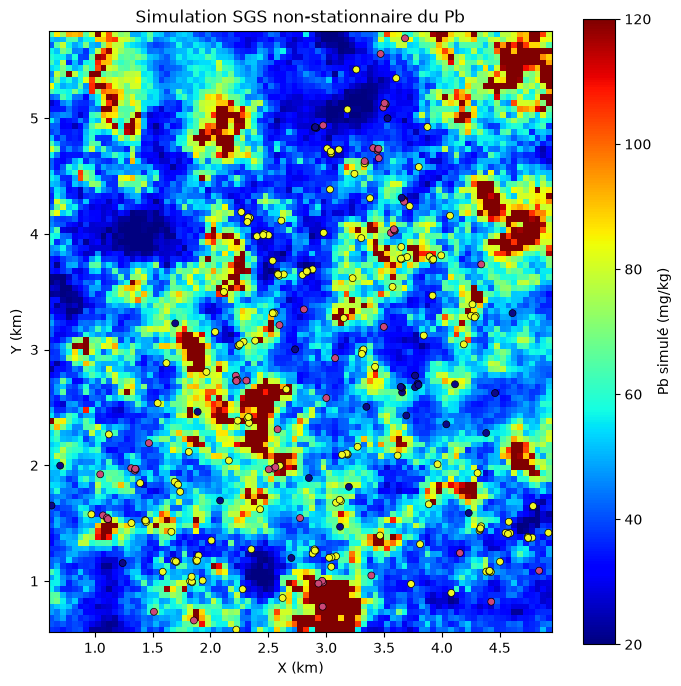

In [28]:
# ---- Carte de la simulation non-stationnaire ----
x_mat = Pred_grid_xy[:, 0].reshape((rows, cols))
y_mat = Pred_grid_xy[:, 1].reshape((rows, cols))
mat = sgs_trans.reshape((rows, cols))

plt.figure(figsize=(7, 7))
im = plt.pcolormesh(x_mat, y_mat, mat, cmap="jet", vmin=20, vmax=120)
plt.colorbar(im, label="Pb simulé (mg/kg)")

# superposition des points originaux, colorés par cluster
plt.scatter(df["X"], df["Y"], c=df["K"], cmap=plt.get_cmap("plasma", n_clusters),
            edgecolor="black", linewidth=0.5, s=25)

plt.title("Simulation SGS non-stationnaire du Pb")
plt.xlabel("X (km)")
plt.ylabel("Y (km)")
plt.axis("scaled")
plt.tight_layout()
plt.show()

## 11. Simulation avec anisotropie

On refait tourner la simulation en modifiant les paramètres de variogramme par cluster : anisotropie à 45° pour le cluster 0, palier renforcé (+30%) pour le cluster 1, et anisotropie à 90° pour le cluster 2. Cela permet d'observer séparément l'effet d'une direction de continuité privilégiée et celui d'une variabilité accrue sur l'aspect de la carte simulée.

In [29]:
# ---- Simulation avec anisotropie ----
gammas_aniso = []
for i, k in enumerate(clusters):
    portee = parametres[k]["range"]
    palier = parametres[k]["sill"]

    if i == 0:
        gammas_aniso.append([45, nug, portee + 0.5, portee, palier, vtype])
    elif i == 1:
        gammas_aniso.append([azimuth, nug, portee, portee, palier * 1.3, vtype])
    else:
        gammas_aniso.append([90, nug, portee + 0.5, portee, palier, vtype])

df_gamma_aniso = pd.DataFrame({"Variogram": gammas_aniso})

sgs_aniso = gs.Interpolation.cluster_sgs(
    Pred_grid_xy, df, "X", "Y", "NPb", "K", k_voisins, df_gamma_aniso, rad
)
sgs_aniso = sgs_aniso.reshape(-1, 1)
sgs_aniso_trans = nst_trans.inverse_transform(sgs_aniso)

print("Simulation anisotrope terminée.")
print(f"Pb simulé (anisotrope) — min={sgs_aniso_trans.min():.1f}, max={sgs_aniso_trans.max():.1f}, "
      f"moyenne={sgs_aniso_trans.mean():.1f} mg/kg")

100%|██████████| 9048/9048 [02:29<00:00, 60.45it/s]

Simulation anisotrope terminée.
Pb simulé (anisotrope) — min=19.0, max=229.6, moyenne=52.5 mg/kg


## 12. Comparaison isotrope vs anisotrope

Les deux cartes sont affichées pour comparer directement la simulation isotrope (Simulation 1, paramètres issus de l'ajustement automatique) et la simulation anisotrope (Simulation 2, paramètres modifiés manuellement pour introduire une direction privilégiée).

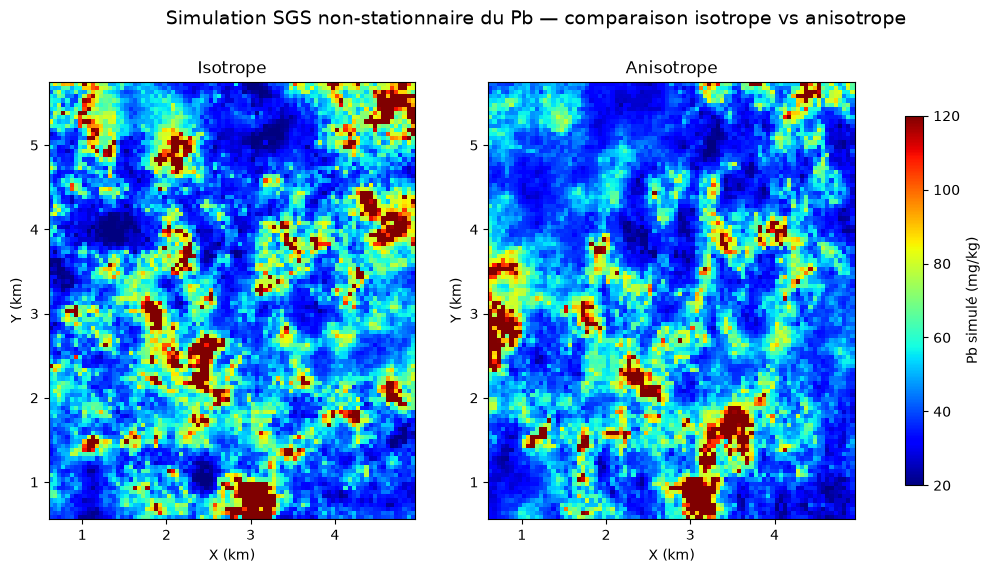

In [30]:
# ---- Comparaison des deux cartes ----
mat_aniso = sgs_aniso_trans.reshape((rows, cols))

fig, axs = plt.subplots(1, 2, figsize=(13, 6))

for ax, m, titre in zip(axs, [mat, mat_aniso], ["Isotrope", "Anisotrope"]):
    im = ax.pcolormesh(x_mat, y_mat, m, cmap="jet", vmin=20, vmax=120)
    ax.set_title(titre)
    ax.set_xlabel("X (km)")
    ax.set_ylabel("Y (km)")
    ax.axis("scaled")

fig.colorbar(im, ax=axs, label="Pb simulé (mg/kg)", shrink=0.8)
fig.suptitle("Simulation SGS non-stationnaire du Pb — comparaison isotrope vs anisotrope", fontsize=14)
gutils.sauvegarder_figure("fig13_simulation_SGS.png") 
plt.show()

## Conclusion

La simulation SGS non-stationnaire attribue à chaque cellule le variogramme du cluster **Landuse** le plus proche, représentant ainsi une variabilité spatiale du Pb différente selon l'occupation du sol, contrairement au notebook 04 (comportement spatial unique).

**Limites** : cluster Culture exclu (5 points, insuffisant) ; nécessite `numpy<2.0` pour fonctionner avec `gstatsim`.